In [100]:
from dotenv import load_dotenv
import os
from pathlib import Path
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import utils.AmexMetrics as AmexMetrics
from models.TabTransformer import run_experiment as run_experiment_c, infer_tabtransformer as infer_tabtransformer_c
from models.qCLSTabTransformer import run_experiment as run_experiment_q, infer_tabtransformer as infer_tabtransformer_q
from utils.Preprocessor import preprocess_amex
from utils.CheckpointHandler import checkpoint_from_model, model_from_checkpoint

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [101]:
#Use .env file with Kaggle API Token to download AMEX dataset
load_dotenv()
os.environ["KAGGLE_API_TOKEN"] = os.getenv("KAGGLE_API_TOKEN")
path = kagglehub.competition_download("amex-default-prediction")
file = os.path.join(path, "train_data.csv")
data_all = pd.read_csv(file, nrows=1e6)
file = os.path.join(path, "train_labels.csv")
labels_all = pd.read_csv(file,nrows=1e6)

In [102]:
def load_models(num_models):
    models_c = []
    models_q = []
    for i in range(num_models):
        path_c = Path(f"../checkpoints/classical_model_seed{i}.pt")
        path_q = Path(f"../checkpoints/quantum_model_(4,2,2)_seed{i}.pt")

        if path_c.is_file():
            models_c.append(model_from_checkpoint(torch.load(f"../checkpoints/classical_model_seed{i}.pt", map_location="cpu", weights_only=True)))
        else:
            models_c.append(None)

        if path_q.is_file():
            models_q.append(model_from_checkpoint(torch.load(f"../checkpoints/quantum_model_(4,2,2)_seed{i}.pt", map_location="cpu", weights_only=True)))
        else:
            models_q.append(None)
            
    return models_c, models_q

def get_metrics(targets, probs):
    y_true_c = pd.DataFrame({"target": targets})
    y_pred_c = pd.DataFrame({"prediction": probs})
    M_c = AmexMetrics.amex_metric(y_true_c, y_pred_c)
    g_c = AmexMetrics.normalized_weighted_gini(y_true_c, y_pred_c)
    d_c = AmexMetrics.top_four_percent_captured(y_true_c, y_pred_c)
    return M_c, g_c, d_c

def run_statistical_analysis(num_seeds, model_c, model_q):
    Ms_c_2000 = []
    Ms_q_2000 = []
    gs_c_2000 = []
    gs_q_2000 = []
    ds_c_2000 = []
    ds_q_2000 = []

    Ms_c_6000 = []
    Ms_q_6000 = []
    gs_c_6000 = []
    gs_q_6000 = []
    ds_c_6000 = []
    ds_q_6000 = []

    for seed in range(num_seeds):
        inference_sizes = [2000, 6000]

        #Scrape all data associated with the a random n customers
        customers = data_all["customer_ID"].drop_duplicates().sample(n=np.max(inference_sizes), random_state=seed)
        data_without_labels = data_all[data_all["customer_ID"].isin(customers)]
        labels = labels_all[labels_all["customer_ID"].isin(customers)]
        inference_df = preprocess_amex(data_without_labels, labels)
        feature_cols = model_c.feature_cols
        inference_df = inference_df.reindex(columns=feature_cols + ["Class"], fill_value=0)

        #Classical model inference
        results = infer_tabtransformer_c(model_c, inference_df)
        probs_c_all = results['probs']
        targets_c_all = results['targets']

        #Quantum model inference
        results = infer_tabtransformer_q(model_q, inference_df)
        probs_q_all = results['probs']
        targets_q_all = results['targets']

        #Calculates inference metrics by size grouping to visualize scaling
        size = 2000

        M, g, d = get_metrics(targets_c_all[:size], probs_c_all[:size])
        gs_c_2000.append(g)
        ds_c_2000.append(d)
        Ms_c_2000.append(M)

        M, g, d = get_metrics(targets_q_all[:size], probs_q_all[:size])
        gs_q_2000.append(g)
        ds_q_2000.append(d)
        Ms_q_2000.append(M)

        #Calculates inference metrics by size grouping to visualize scaling
        size = 6000

        M, g, d = get_metrics(targets_c_all[:size], probs_c_all[:size])
        gs_c_6000.append(g)
        ds_c_6000.append(d)
        Ms_c_6000.append(M)

        M, g, d = get_metrics(targets_q_all[:size], probs_q_all[:size])
        gs_q_6000.append(g)
        ds_q_6000.append(d)
        Ms_q_6000.append(M)

    metrics = [Ms_c_2000, 
        gs_c_2000, 
        ds_c_2000, 
        Ms_q_2000,
        gs_q_2000,
        ds_q_2000,
        Ms_c_6000,
        gs_c_6000,
        ds_c_6000,
        Ms_q_6000,
        gs_q_6000,
        ds_q_6000,
    ]

    return metrics

In [103]:
def plot_M(metrics, num_seeds, quantum_label):
    M_means_c = [np.mean(metrics[0]), np.mean(metrics[6])]
    M_ses_c = [np.std(metrics[0], ddof=1)/np.sqrt(num_seeds), np.std(metrics[6], ddof=1)/np.sqrt(num_seeds)]
    M_means_q = [np.mean(metrics[3]), np.mean(metrics[9])]
    M_ses_q = [np.std(metrics[3], ddof=1)/np.sqrt(num_seeds), np.std(metrics[9], ddof=1)/np.sqrt(num_seeds)]

    x = np.array([0, 1])
    offset = 0.05

    plt.errorbar(x - offset, M_means_c, yerr=M_ses_c, fmt='o', capsize=5, ecolor='black', color='blue', label='Classical')
    plt.errorbar(x + offset, M_means_q, yerr=M_ses_q, fmt='o', capsize=5, ecolor='black', color='red', label=quantum_label)
    plt.xticks(x, ['2000', '6000'])
    plt.xlabel('Inference Size')
    plt.ylabel('AmEx Proposed Metric')
    plt.title('Inference for AmEx Default Prediction on 30k param models')
    plt.legend()
    plt.show()

def plot_G(metrics, num_seeds, quantum_label):
    G_means_c = [np.mean(metrics[1]), np.mean(metrics[7])]
    G_ses_c = [np.std(metrics[1], ddof=1)/np.sqrt(num_seeds), np.std(metrics[7], ddof=1)/np.sqrt(num_seeds)]
    G_means_q = [np.mean(metrics[4]), np.mean(metrics[10])]
    G_ses_q = [np.std(metrics[4], ddof=1)/np.sqrt(num_seeds), np.std(metrics[10], ddof=1)/np.sqrt(num_seeds)]

    x = np.array([0, 1])
    offset = 0.05

    plt.errorbar(x - offset, G_means_c, yerr=G_ses_c, fmt='o', capsize=5, ecolor='black', color='blue', label='Classical')
    plt.errorbar(x + offset, G_means_q, yerr=G_ses_q, fmt='o', capsize=5, ecolor='black', color='red', label=quantum_label)
    plt.xticks(x, ['2000', '6000'])
    plt.xlabel('Inference Size')
    plt.ylabel('G')
    plt.title('Inference Normalized Gini Coefficient for 30k param models')
    plt.legend()
    plt.show()

def plot_D(metrics, num_seeds, quantum_label):
    D_means_c = [np.mean(metrics[2]), np.mean(metrics[8])]
    D_ses_c = [np.std(metrics[2], ddof=1)/np.sqrt(num_seeds), np.std(metrics[8], ddof=1)/np.sqrt(num_seeds)]
    D_means_q = [np.mean(metrics[5]), np.mean(metrics[11])]
    D_ses_q = [np.std(metrics[5], ddof=1)/np.sqrt(num_seeds), np.std(metrics[11], ddof=1)/np.sqrt(num_seeds)]

    x = np.array([0, 1])
    offset = 0.05

    plt.errorbar(x - offset, D_means_c, yerr=D_ses_c, fmt='o', capsize=5, ecolor='black', color='blue', label='Classical')
    plt.errorbar(x + offset, D_means_q, yerr=D_ses_q, fmt='o', capsize=5, ecolor='black', color='red', label=quantum_label)
    plt.xticks(x, ['2000', '6000'])
    plt.xlabel('Inference Size')
    plt.ylabel('D')
    plt.title('Inference Default Rate at 4% for 30k param models')
    plt.legend()
    plt.show()

In [ ]:
num_seeds = 5
qufex_params = (4,2,2)
entangling = True

save_dir_models = Path("../checkpoints")
save_dir_models.mkdir(parents=True, exist_ok=True)

#Train multiple models over different seeds of training data
for seed in range(num_seeds):
    #Scrape all data associated with the a random n customers
    customers = data_all["customer_ID"].drop_duplicates().sample(n=12000, random_state=seed)
    data_without_labels = data_all[data_all["customer_ID"].isin(customers)]
    labels = labels_all[labels_all["customer_ID"].isin(customers)]
    data = preprocess_amex(data_without_labels, labels)
    frac_fraud = np.sum(data['Class'])/len(data['Class'])

    fraud_data = data[data['Class'] == 1].sample(frac=1, random_state=42)
    non_fraud_data = data[data['Class'] == 0].sample(frac=1, random_state=42)

    train_size = 2000
    training_fraud = int(frac_fraud*train_size)
    data_subset = pd.concat([fraud_data[:training_fraud], non_fraud_data[:train_size - training_fraud]]).sample(frac=1, random_state=42)

    #Run classical experiment on small dataset
    model_c, test_results_c, test_df = run_experiment_c(data_subset, lr=1e-3)
    torch.save(checkpoint_from_model(model_c), save_dir_models / f"classical_model_seed{seed}.pt")
    print(f'Classical model test Amex metric: {test_results_c["amex_metric"]}, Seed={seed}')

    #Run quantum experiment on small dataset
    model_q, test_results_q, test_df = run_experiment_q(data_subset, lr=7e-4, qufex_params=qufex_params, entangling=entangling)
    torch.save(checkpoint_from_model(model_q), save_dir_models / f"quantum_model_(4,2,2)_seed{seed}.pt")
    print(f'Quantum CLS model test Amex metric: {test_results_q["amex_metric"]}, Seed={seed}, QuFeX{qufex_params}\n')

Classical model test Amex metric: 0.6743663292407238, Seed=0
Quantum CLS model test Amex metric: 0.7259574001984346, Seed=0, QuFeX(4, 2, 2)

Classical model test Amex metric: 0.7482163545180545, Seed=1
Quantum CLS model test Amex metric: 0.7383284365962566, Seed=1, QuFeX(4, 2, 2)

Classical model test Amex metric: 0.6953478149906722, Seed=2
Quantum CLS model test Amex metric: 0.8048845405988265, Seed=2, QuFeX(4, 2, 2)

Classical model test Amex metric: 0.6587652834333333, Seed=3
Quantum CLS model test Amex metric: 0.6438225724636513, Seed=3, QuFeX(4, 2, 2)

Classical model test Amex metric: 0.6558015486182709, Seed=4
Quantum CLS model test Amex metric: 0.6737461694106817, Seed=4, QuFeX(4, 2, 2)



In [ ]:
num_seeds = 8
models_c, models_q = load_models(num_models=5)

#Select best models from training
best_model_idx_c = [1, 2, 0] #With best model first
best_model_idx_q = [2, 1, 0]
best_models_c = [models_c[x] for x in best_model_idx_c]
best_models_q = [models_q[x] for x in best_model_idx_q]

metrics = []

save_dir_metrics = Path("../metrics")
save_dir_metrics.mkdir(parents=True, exist_ok=True)

for i in range(len(best_models_q)):
    results = run_statistical_analysis(num_seeds=num_seeds, model_c=best_models_c[i], model_q=best_models_q[i])
    c, q = best_model_idx_c[i], best_model_idx_q[i]
    np.save(save_dir_metrics / f"422_seeds{c}_{q}", results)
    print(f"Finished analysis for classical seed={c}, quantum seed={q}")

Finished analysis for classical seed=1, quantum seed=2
Finished analysis for classical seed=2, quantum seed=1
Finished analysis for classical seed=0, quantum seed=0


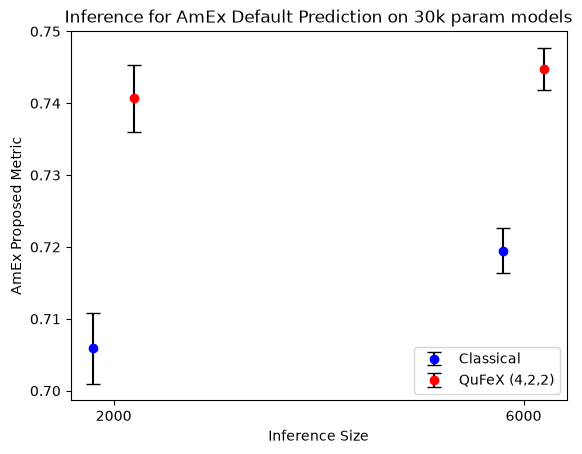

In [ ]:
metrics = np.load(save_dir_metrics / "422_seeds1_2.npy")
plot_M(metrics, num_seeds=num_seeds, quantum_label="QuFeX (4,2,2)")

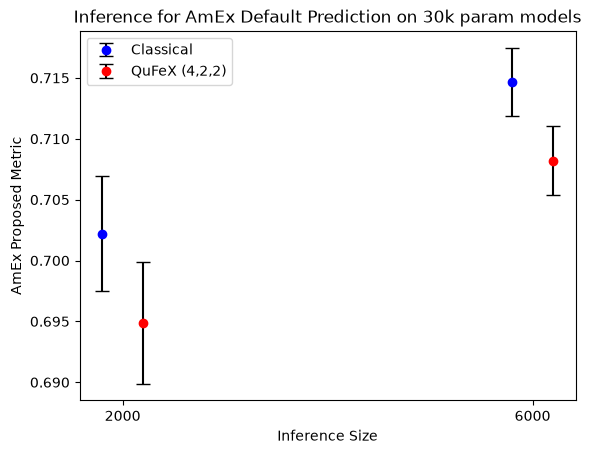

In [ ]:
metrics = np.load(save_dir_metrics / "422_seeds2_1.npy")
plot_M(metrics, num_seeds=num_seeds, quantum_label="QuFeX (4,2,2)")

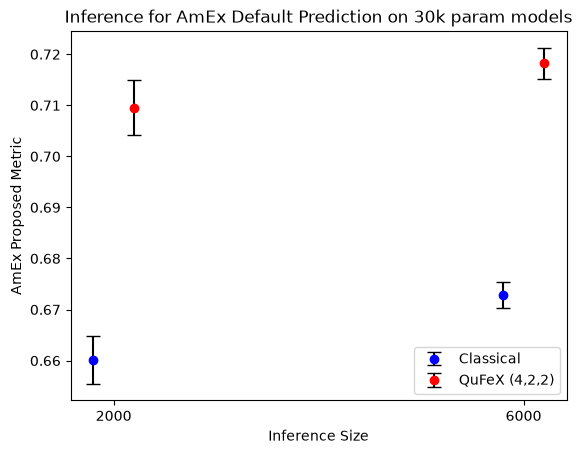

In [ ]:
metrics = np.load(save_dir_metrics / "422_seeds0_0.npy")
plot_M(metrics, num_seeds=num_seeds, quantum_label="QuFeX (4,2,2)")